# Vérification de deux points du rapport avant correction

Ce notebook teste deux affirmations de `rapport_TP3.tex` **sans rien modifier** :

1. **Partie 2, ligne ~289** : « une mesure d'angle à $t = 30$ s apporte environ $10^4$ fois moins d'information qu'une mesure à $t = 1$ s ».
2. **Partie 1, Q1b, ligne ~197** : « avec un pas de $0{,}1^\circ$ on obtient $115^\circ$ et $13\,349{,}589$ m² ; avec un pas de $0{,}01^\circ$, $114{,}9^\circ$ et $13\,349{,}546$ m² ».

À lancer depuis le dossier `Partie_Mohamed/`. La partie 2 utilise le code de `Partie_Mohamed/` ; la Q1 utilise le code **complété de Fatimetou à la racine du dépôt** (les copies de `Partie_Mohamed/` sont encore des brouillons).

In [1]:
import sys, importlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == 'Partie_Mohamed' else HERE
PARTIE = ROOT / 'Partie_Mohamed'
print('Code partie 2 :', PARTIE)
print('Code Q1       :', ROOT)

Code partie 2 : /Users/mohamed/TP3_code/Partie_Mohamed
Code Q1       : /Users/mohamed/TP3_code


## 1. Décroissance de l'information de mesure (partie 2)

Pour un azimut, l'information apportée par une mesure est
$$H^\top R^{-1} H = \frac{y_c^2}{\sigma_\theta^2\, r^4}\begin{pmatrix}1&0\\0&0\end{pmatrix}, \qquad r^2 = (s-x_c)^2 + y_c^2 .$$

### 1.a Calcul à la main, sur la trajectoire moyenne $s \approx 5t$

In [2]:
xc, yc = 0.0, -20.0
s = lambda t: 5.0 * t                  # position moyenne : s0 = 0, v0 = 5 m/s
r2 = lambda t: (s(t) - xc)**2 + yc**2

for t in (1, 30):
    print(f't = {t:2d} s : s = {s(t):6.1f} m, r^2 = {r2(t):8.0f} m^2')

ratio = (r2(30) / r2(1))**2            # information en 1/r^4
print(f'\nInformation(t=1) / Information(t=30) = {ratio:,.0f}')

t =  1 s : s =    5.0 m, r^2 =      425 m^2
t = 30 s : s =  150.0 m, r^2 =    22900 m^2

Information(t=1) / Information(t=30) = 2,903


### 1.b Avec le vrai code : espérance Monte-Carlo de $H^\top R^{-1}H$

On reprend exactement ce que fait `information_curve` dans `experiments.py` : on tire des échantillons selon la loi a priori, on les propage avec la dynamique, et on moyenne $H^\top R^{-1} H$ (composante $ss$) à chaque instant.

In [3]:
sys.path.insert(0, str(PARTIE))
import experiments as e
from cramer_rao_general import expected_measurement_information

def info_curve(Q, n_steps=30, mc=15000, seed=2027):
    rng = np.random.default_rng(seed)
    samples = rng.multivariate_normal(e.X0_MEAN, e.P0, size=mc)
    noise_std = np.sqrt(np.diag(Q))
    info = np.empty(n_steps + 1)
    info[0] = np.nan
    for k in range(1, n_steps + 1):
        samples = samples @ e.F.T + rng.normal(size=samples.shape) * noise_std
        info[k] = expected_measurement_information(e.h_jac, e.R, samples)[0, 0]
    return info

info_Q0 = info_curve(np.zeros_like(e.Q))
info_Q = info_curve(e.Q, seed=3031)

for name, info in (('Q = 0', info_Q0), ('Q != 0', info_Q)):
    print(f'{name:7s} : info(k=1) = {info[1]:.3e}, info(k=30) = {info[30]:.3e}, '
          f'rapport = {info[1] / info[30]:,.0f}')

Q = 0   : info(k=1) = 5.716e+00, info(k=30) = 4.607e-03, rapport = 1,241
Q != 0  : info(k=1) = 5.712e+00, info(k=30) = 5.103e-03, rapport = 1,119


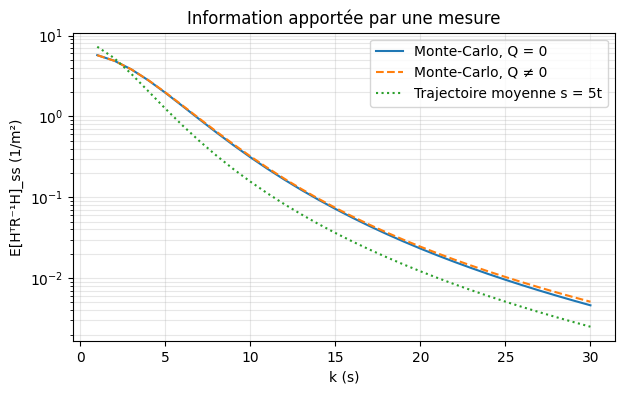

In [4]:
k = np.arange(31)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(k[1:], info_Q0[1:], label='Monte-Carlo, Q = 0')
ax.semilogy(k[1:], info_Q[1:], '--', label='Monte-Carlo, Q ≠ 0')
ax.semilogy(k[1:], yc**2 / (e.R[0, 0] * r2(k[1:])**2), ':', label='Trajectoire moyenne s = 5t')
ax.set(xlabel='k (s)', ylabel='E[HᵀR⁻¹H]_ss (1/m²)', title='Information apportée par une mesure')
ax.grid(alpha=.3, which='both')
ax.legend()
plt.show()

**À comparer avec le rapport** : le texte dit « environ $10^4$ fois ». Si les rapports affichés ci-dessus sont de l'ordre de $3\times10^3$, il faut écrire « environ 3 000 fois » (ou « plus de $10^3$ fois »).

## 2. Pas de la grille en Q1b (partie 1)

On relance la recherche de l'angle optimal avec `evaluate_phi` (code de Fatimetou, à la racine), pour trois pas : $1^\circ$, $0{,}1^\circ$ et $0{,}01^\circ$. La boucle reproduit celle de `main()` sans écrire de figures.

⚠️ Le pas de $0{,}01^\circ$ évalue 36 000 angles : compter environ une minute.

In [5]:
# Charger le code Q1 de la racine (et non les brouillons de Partie_Mohamed)
for name in ('q1_manoeuvre', 'cramer_rao_deterministe'):
    sys.modules.pop(name, None)
sys.path.insert(0, str(ROOT))
import q1_manoeuvre as q1
print('q1_manoeuvre chargé depuis :', q1.__file__)

def search(step_deg):
    grid = np.arange(0., 360. + 1e-10, step_deg)
    grid = grid[grid < 360.]
    costs = np.array([q1.evaluate_phi(p)[0] for p in grid])
    best = int(np.argmin(costs))
    return grid[best], costs[best]

results = {}
for step in (1.0, 0.1, 0.01):
    phi, crit = search(step)
    results[step] = (phi, crit)
    print(f'pas = {step:5.2f}° : phi_opt = {phi:7.2f}°, C_min = {crit:10.3f} m², RMS = {np.sqrt(crit):.3f} m')

q1_manoeuvre chargé depuis : /Users/mohamed/TP3_code/q1_manoeuvre.py
pas =  1.00° : phi_opt =  115.00°, C_min =  13349.589 m², RMS = 115.540 m
pas =  0.10° : phi_opt =  114.90°, C_min =  13349.547 m², RMS = 115.540 m
pas =  0.01° : phi_opt =  114.88°, C_min =  13349.546 m², RMS = 115.540 m


**À comparer avec le rapport** :

| Rapport | Pas annoncé | $\varphi_{\mathrm{opt}}$ | $C_{\min}$ (m²) |
|---|---|---|---|
| 1ʳᵉ exécution | $0{,}1^\circ$ | $115^\circ$ | $13\,349{,}589$ |
| 2ᵉ exécution | $0{,}01^\circ$ | $114{,}9^\circ$ | $13\,349{,}546$ |

Regarder quel pas donne réellement $115^\circ$ et $13\,349{,}589$ m² dans le tableau ci-dessus.